In [1]:
from utils import load_counties, load_cbsa, set_plot_style, find_nri_future_risk

import pandas as pd
import numpy as np
import geopandas as gpd

import statsmodels.formula.api as smf
import statsmodels.api as sm

from scipy import stats

import patsy

from statsmodels.iolib.summary2 import summary_col
from scipy.stats import spearmanr

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import matplotlib as mpl

import pickle

import scipy

https://github.com/fulton-ring/nri-future-risk/blob/main/public/NRI_Data_Dictionary.xlsx

In [2]:
set_plot_style()


In [3]:
nri_county=pd.read_parquet("../data_loaded/nri_counties.parquet")

In [4]:
nri_future = pd.read_excel(find_nri_future_risk())


In [5]:
counties = load_counties()


In [6]:
nri_future["STCOFIPS"]=nri_future["STCOFIPS"].astype(str).str.zfill(5)

In [7]:
df = nri_future[['STCOFIPS', 'CFLD_RISKS', 'CFLD_MID_LOWER_PRISKS', 'CFLD_MID_HIGHER_PRISKS', 'CFLD_LATE_LOWER_PRISKS', 'CFLD_LATE_HIGHER_PRISKS', 
                 'DRGT_RISKS', 'DRGT_MID_LOWER_PRISKS', 'DRGT_MID_HIGHER_PRISKS', 'DRGT_LATE_LOWER_PRISKS', 'DRGT_LATE_HIGHER_PRISKS', 'EXHT_RISKS', 
                 'EXHT_L99_MID_LOWER_PRISKS', 'EXHT_L99_MID_HIGHER_PRISKS', 'EXHT_L99_LATE_LOWER_PRISKS', 'EXHT_L99_LATE_HIGHER_PRISKS', 
                 'HRCN_RISKS', 'HRCN_MID_LOWER_PRISKS', 'HRCN_MID_HIGHER_PRISKS', 'HRCN_LATE_LOWER_PRISKS', 'HRCN_LATE_HIGHER_PRISKS', 
                 'WFIR_RISKS', 'WFIR_MID_LOWER_PRISKS', 'WFIR_MID_HIGHER_PRISKS', 'WFIR_LATE_LOWER_PRISKS', 'WFIR_LATE_HIGHER_PRISKS']].copy()

# mapping: base risk -> (mid lower, mid higher, late lower, late higher)
risk_pairs = {
    "CFLD": (
        "CFLD_MID_LOWER_PRISKS", "CFLD_MID_HIGHER_PRISKS",
        "CFLD_LATE_LOWER_PRISKS", "CFLD_LATE_HIGHER_PRISKS"
    ),
    "DRGT": (
        "DRGT_MID_LOWER_PRISKS", "DRGT_MID_HIGHER_PRISKS",
        "DRGT_LATE_LOWER_PRISKS", "DRGT_LATE_HIGHER_PRISKS"
    ),
    "EXHT_L99": (
        "EXHT_L99_MID_LOWER_PRISKS", "EXHT_L99_MID_HIGHER_PRISKS",
        "EXHT_L99_LATE_LOWER_PRISKS", "EXHT_L99_LATE_HIGHER_PRISKS"
    ),
    "HRCN": (
        "HRCN_MID_LOWER_PRISKS", "HRCN_MID_HIGHER_PRISKS",
        "HRCN_LATE_LOWER_PRISKS", "HRCN_LATE_HIGHER_PRISKS"
    ),
    "WFIR": (
        "WFIR_MID_LOWER_PRISKS", "WFIR_MID_HIGHER_PRISKS",
        "WFIR_LATE_LOWER_PRISKS", "WFIR_LATE_HIGHER_PRISKS"
    )
}

for risk, (mid_l, mid_h, late_l, late_h) in risk_pairs.items():
    df[f"{risk}_MID_MEAN_PRISKS"] = df[[mid_l, mid_h]].mean(axis=1, skipna=True)
    df[f"{risk}_LATE_MEAN_PRISKS"] = df[[late_l, late_h]].mean(axis=1, skipna=True)

In [8]:
base_risk_cols = [
    "CFLD_RISKS",
    "DRGT_RISKS",
    "EXHT_RISKS",
    "HRCN_RISKS",
    "WFIR_RISKS"
]

In [9]:
hazards = ["CFLD", "DRGT", "EXHT_L99", "HRCN", "WFIR"]

keep_cols = ["STCOFIPS"] + base_risk_cols

for h in hazards:
    keep_cols.extend([
        f"{h}_MID_MEAN_PRISKS",
        f"{h}_LATE_MEAN_PRISKS"
    ])

df = df[keep_cols].copy()


In [10]:
haz_current = [
    "CFLD_RISKS",
    "DRGT_RISKS",
    "EXHT_RISKS",
    "HRCN_RISKS",
    "WFIR_RISKS"
]

haz_mid = [
    "CFLD_MID_MEAN_PRISKS",
    "DRGT_MID_MEAN_PRISKS",
    "EXHT_L99_MID_MEAN_PRISKS",
    "HRCN_MID_MEAN_PRISKS",
    "WFIR_MID_MEAN_PRISKS"
]

haz_late = [
    "CFLD_LATE_MEAN_PRISKS",
    "DRGT_LATE_MEAN_PRISKS",
    "EXHT_L99_LATE_MEAN_PRISKS",
    "HRCN_LATE_MEAN_PRISKS",
    "WFIR_LATE_MEAN_PRISKS"
]

df["haz_composite_mean"] = (
    df[haz_current]
    .fillna(0)
    .mean(axis=1)
)

df["haz_composite_mid"] = (
    df[haz_mid]
    .fillna(0)
    .mean(axis=1)
)

df["haz_composite_late"] = (
    df[haz_late]
    .fillna(0)
    .mean(axis=1)
)

In [11]:
counties['STCOFIPS']=counties['STCOFIPS'].astype(str)
df['STCOFIPS']=df['STCOFIPS'].astype(str)

counties_=counties.merge(df, how='left')

In [12]:
hazards = {
    "CFLD": "CFLD_LATE_MEAN_PRISKS",
    "DRGT": "DRGT_LATE_MEAN_PRISKS",
    "EXHT": "EXHT_L99_LATE_MEAN_PRISKS",
    "HRCN": "HRCN_LATE_MEAN_PRISKS",
    "WFIR": "WFIR_LATE_MEAN_PRISKS",
}

for h, future_col in hazards.items():
    current_col = f"{h}_RISKS"
    pct_col = f"{h}_LATE_PCT_CHANGE"

    counties_[pct_col] = (
        (counties_[future_col] - counties_[current_col])
        / (counties_[current_col]+0.01)
    ) * 100

    # remove infinities and invalid values
    counties_.loc[
        ~np.isfinite(counties_[pct_col]),
        pct_col
    ] = np.nan

### composite
counties_['haz_composite_RISKS']=counties_['haz_composite_mean']
counties_['haz_composite_LATE_PCT_CHANGE'] = (
    (counties_['haz_composite_late'] - counties_['haz_composite_mean'])
    / counties_['haz_composite_mean']
) * 100

# remove infinities and invalid values
counties_.loc[
    ~np.isfinite(counties_['haz_composite_LATE_PCT_CHANGE']),
    'haz_composite_LATE_PCT_CHANGE'
] = np.nan

In [13]:
counties_.columns 

Index(['STATEFP', 'COUNTYFP', 'COUNTYNS', 'AFFGEOID', 'GEOID', 'NAME', 'LSAD',
       'ALAND', 'AWATER', 'geometry', 'GEOIDFQ', 'NAMELSAD', 'STUSPS',
       'STATE_NAME', 'STCOFIPS', 'STATE', 'name', 'CFLD_RISKS', 'DRGT_RISKS',
       'EXHT_RISKS', 'HRCN_RISKS', 'WFIR_RISKS', 'CFLD_MID_MEAN_PRISKS',
       'CFLD_LATE_MEAN_PRISKS', 'DRGT_MID_MEAN_PRISKS',
       'DRGT_LATE_MEAN_PRISKS', 'EXHT_L99_MID_MEAN_PRISKS',
       'EXHT_L99_LATE_MEAN_PRISKS', 'HRCN_MID_MEAN_PRISKS',
       'HRCN_LATE_MEAN_PRISKS', 'WFIR_MID_MEAN_PRISKS',
       'WFIR_LATE_MEAN_PRISKS', 'haz_composite_mean', 'haz_composite_mid',
       'haz_composite_late', 'CFLD_LATE_PCT_CHANGE', 'DRGT_LATE_PCT_CHANGE',
       'EXHT_LATE_PCT_CHANGE', 'HRCN_LATE_PCT_CHANGE', 'WFIR_LATE_PCT_CHANGE',
       'haz_composite_RISKS', 'haz_composite_LATE_PCT_CHANGE'],
      dtype='object')

In [14]:
cbsa = load_cbsa()
counties_=counties_.merge(cbsa[['CBSA Code', 'CBSA Title', 'STCOFIPS']], on='STCOFIPS', how='left')

cbsa_gdf = counties_.dissolve(
    by='CBSA Code',
    as_index=False
)
cbsa_gdf=cbsa_gdf.drop(columns=['name'])
cbsa_gdf=cbsa_gdf.rename(columns={'CBSA Title':'name', 'CBSA Code':'CBSA'})

In [15]:
risk_vars = [
    'CFLD_RISKS', 'DRGT_RISKS', 'EXHT_RISKS', 'HRCN_RISKS', 'WFIR_RISKS',
    'CFLD_LATE_MEAN_PRISKS', 'DRGT_LATE_MEAN_PRISKS',
    'EXHT_L99_LATE_MEAN_PRISKS', 'HRCN_LATE_MEAN_PRISKS',
    'WFIR_LATE_MEAN_PRISKS'
]

cbsa_agg = (
    counties_
    .groupby(['CBSA Code', 'CBSA Title'])
    .agg({col: lambda x: x.mean(skipna=False) for col in risk_vars})
    .reset_index()
)

In [16]:
cbsa_agg = (cbsa_gdf[['CBSA', 'name', 'geometry']]
             .merge(cbsa_agg, left_on='CBSA', right_on='CBSA Code')
            )

In [17]:
cbsa_agg["haz_composite_mean"] = (
    cbsa_agg[haz_current]
    .fillna(0)
    .mean(axis=1)
)

cbsa_agg["haz_composite_late"] = (
    cbsa_agg[haz_late]
    .fillna(0)
    .mean(axis=1)
)


for h, future_col in hazards.items():
    current_col = f"{h}_RISKS"
    pct_col = f"{h}_LATE_PCT_CHANGE"

    cbsa_agg[pct_col] = (
        (cbsa_agg[future_col] - cbsa_agg[current_col])
        / (cbsa_agg[current_col]+0.01)
    ) * 100

    # remove infinities and invalid values
    cbsa_agg.loc[
        ~np.isfinite(cbsa_agg[pct_col]),
        pct_col
    ] = np.nan

### composite
cbsa_agg['haz_composite_RISKS']=cbsa_agg['haz_composite_mean']
cbsa_agg['haz_composite_LATE_PCT_CHANGE'] = (
    (cbsa_agg['haz_composite_late'] - cbsa_agg['haz_composite_mean'])
    / cbsa_agg['haz_composite_mean']
) * 100

# remove infinities and invalid values
cbsa_agg.loc[
    ~np.isfinite(cbsa_agg['haz_composite_LATE_PCT_CHANGE']),
    'haz_composite_LATE_PCT_CHANGE'
] = np.nan

### CBSA

In [18]:
cates_all=pd.read_csv('../data_generated/cf_results/cf_continuous_summary.csv')

In [19]:
def _ate(h): return cates_all.loc[cates_all['hazard'] == h, 'ATE_est'].iloc[0]
def _se(h):  return cates_all.loc[cates_all['hazard'] == h, 'ATE_se'].iloc[0]

risk_cfld = _ate('CFLD_RISKS')
risk_drgt = _ate('DRGT_RISKS')
risk_hwav = _ate('HWAV_RISKS')
risk_hrcn = _ate('HRCN_RISKS')
risk_wfir = _ate('WFIR_RISKS')
risk_ate  = _ate('RISK_SCORE')

se_cfld = _se('CFLD_RISKS')
se_drgt = _se('DRGT_RISKS')
se_hwav = _se('HWAV_RISKS')
se_hrcn = _se('HRCN_RISKS')
se_wfir = _se('WFIR_RISKS')
se_risk  = _se('RISK_SCORE')


In [20]:
print(risk_cfld, risk_drgt, risk_hwav, risk_hrcn, risk_wfir)

-0.0015660794146432 -0.0002658911709988 -0.0014714369022572 -0.0009901822089921 -0.0007012383389586


In [21]:
risk_cols = [
    "CFLD_LATE_MEAN_PRISKS",
    "CFLD_RISKS",
    "DRGT_LATE_MEAN_PRISKS",
    "DRGT_RISKS",
    "EXHT_L99_LATE_MEAN_PRISKS",
    "EXHT_RISKS",
    "HRCN_LATE_MEAN_PRISKS",
    "HRCN_RISKS",
    "WFIR_LATE_MEAN_PRISKS",
    "WFIR_RISKS"
]

cbsa_agg[risk_cols] = cbsa_agg[risk_cols].fillna(0)

cbsa_agg['risk_change']=cbsa_agg['haz_composite_late']-cbsa_agg['haz_composite_mean']
cbsa_agg['risk_change_cfld']=cbsa_agg['CFLD_LATE_MEAN_PRISKS']-cbsa_agg['CFLD_RISKS']
cbsa_agg['risk_change_drgt']=cbsa_agg['DRGT_LATE_MEAN_PRISKS']-cbsa_agg['DRGT_RISKS']
cbsa_agg['risk_change_exht']=cbsa_agg['EXHT_L99_LATE_MEAN_PRISKS']-cbsa_agg['EXHT_RISKS']
cbsa_agg['risk_change_hrcn']=cbsa_agg['HRCN_LATE_MEAN_PRISKS']-cbsa_agg['HRCN_RISKS']
cbsa_agg['risk_change_wfir']=cbsa_agg['WFIR_LATE_MEAN_PRISKS']-cbsa_agg['WFIR_RISKS']

# cbsa_agg['attractiveness_change']=cbsa_agg['risk_change']*risk_ate

cbsa_agg["attractiveness_change"] = (
    cbsa_agg["risk_change_cfld"] * risk_cfld +
    cbsa_agg["risk_change_drgt"] * risk_drgt +
    cbsa_agg["risk_change_exht"] * risk_hwav +
    cbsa_agg["risk_change_hrcn"] * risk_hrcn +
    cbsa_agg["risk_change_wfir"] * risk_wfir
)

cbsa_agg["attractiveness_change_var"] = (
    (cbsa_agg["risk_change_cfld"] ** 2) * (se_cfld ** 2) +
    (cbsa_agg["risk_change_drgt"] ** 2) * (se_drgt ** 2) +
    (cbsa_agg["risk_change_exht"] ** 2) * (se_hwav ** 2) +
    (cbsa_agg["risk_change_hrcn"] ** 2) * (se_hrcn ** 2) +
    (cbsa_agg["risk_change_wfir"] ** 2) * (se_wfir ** 2)
)

cbsa_agg["attractiveness_change_se"] = np.sqrt(cbsa_agg["attractiveness_change_var"])

cbsa_agg["attractiveness_change_ci_low"] = (
    cbsa_agg["attractiveness_change"] - 1.645 * cbsa_agg["attractiveness_change_se"]
)

cbsa_agg["attractiveness_change_ci_high"] = (
    cbsa_agg["attractiveness_change"] + 1.645 * cbsa_agg["attractiveness_change_se"]
)

In [22]:
cbsa_agg[['haz_composite_LATE_PCT_CHANGE', 'attractiveness_change']].corr(method='spearman')

,haz_composite_LATE_PCT_CHANGE,attractiveness_change
haz_composite_LATE_PCT_CHANGE,1.000000,-0.875152
attractiveness_change,-0.875152,1.000000


In [23]:
cbsa_agg["significant"] = (
    (cbsa_agg["attractiveness_change_ci_low"] > 0) |
    (cbsa_agg["attractiveness_change_ci_high"] < 0)
)

cbsa_agg.significant.value_counts()

significant
True     565
False    363
Name: count, dtype: int64

In [24]:
# Extreme PuOr (higher contrast)
colors_strong = [
    "#7f3b08",   # very deep burnt orange
    "#f2c68b",   # soft orange
    "#fcead6",   # very light near-white
    "#9678d1",   # strong lavender/purple
    "#3f007d"    # very deep purple
]

strong_puor = mcolors.LinearSegmentedColormap.from_list(
    "StrongPuOr", colors_strong, N=256
)


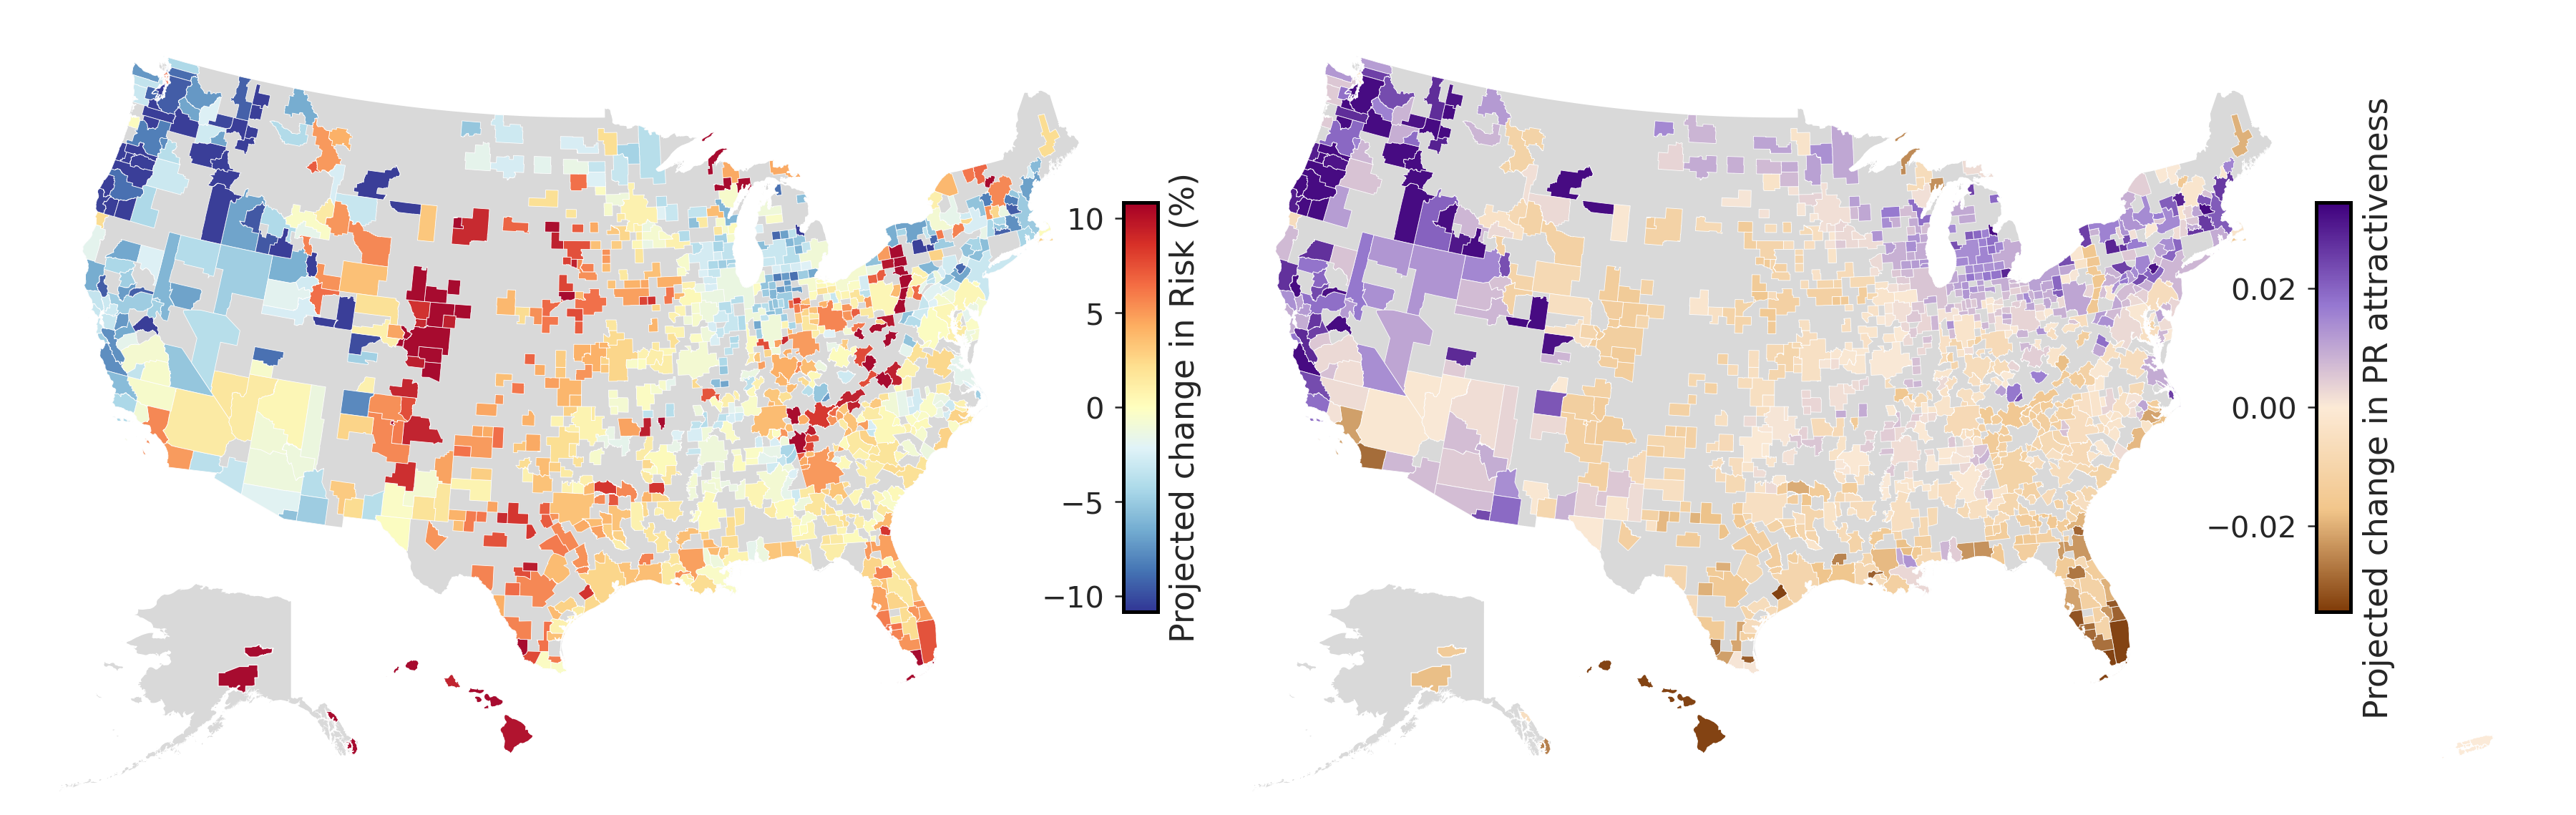

In [25]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# no Alaska, no Hawaii: cbsa codes for alaska and hawaii
cbsa_ak_hi = [
    11260, 21820, 27940, 16220, 28540,  # Alaska
    46520, 27980, 25900, 28180           # Hawaii
]
cbsa_ak_hi = [str(x) for x in cbsa_ak_hi]
not_conus = ["02", "15", "72", "78", "60", "66", "69"]

# -------------------------------------------------------
# Prepare data
# -------------------------------------------------------
counties_5070 = counties.to_crs("EPSG:5070")
counties_4269 = counties.to_crs("EPSG:4269")
usa = cbsa_agg.to_crs("EPSG:5070")
usa_4269 = cbsa_agg.to_crs("EPSG:4269")

conus = usa[~usa["CBSA"].isin(cbsa_ak_hi)]
alaska = usa_4269[usa_4269["CBSA"].isin([str(x) for x in [11260, 21820, 27940, 16220, 28540]])]
hawaii = usa_4269[usa_4269["CBSA"].isin([str(x) for x in [46520, 27980, 25900, 28180]])]

conus_counties = counties_5070[~counties_5070["STATEFP"].isin(not_conus)].copy()
alaska_counties = counties_4269[counties_4269["STATEFP"] == "02"].copy()
hawaii_counties = counties_4269[counties_4269["STATEFP"] == "15"].copy()

conus_outline  = conus_counties[["geometry"]].dissolve()
alaska_outline = alaska_counties[["geometry"]].dissolve()
hawaii_outline = hawaii_counties[["geometry"]].dissolve()

prc_change = "haz_composite_LATE_PCT_CHANGE"
attr_col   = "attractiveness_change"

# -------------------------------------------------------
# Normalisation
# -------------------------------------------------------
pct_vmax  = np.nanpercentile(conus[prc_change], 97)
pct_norm  = TwoSlopeNorm(vmin=-pct_vmax, vcenter=0, vmax=pct_vmax)

attr_vmax = np.nanpercentile(conus[attr_col], 97)
attr_norm = TwoSlopeNorm(vmin=-attr_vmax, vcenter=0, vmax=attr_vmax)

# -------------------------------------------------------
# Helper: draw AK + HI insets on a given axis
# -------------------------------------------------------
def add_ak_hi_insets(ax, column, cmap, norm):
    """Add Alaska and Hawaii insets to the given axes."""

    # --- Alaska inset ---
    ax_ak = inset_axes(
        ax,
        width="100%", height="100%",
        loc="lower left",
        bbox_to_anchor=(0.00, 0.00, 0.28, 0.28),
        bbox_transform=ax.transAxes,
        borderpad=0
    )
    ax_ak.axis("off")

    alaska_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_ak, zorder=1)
    alaska.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.3,
        edgecolor="white",
        ax=ax_ak,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"}
    )
    ax_ak.set_xlim(-180, -129)
    ax_ak.set_ylim(51, 72)

    # --- Hawaii inset ---
    ax_hi = inset_axes(
        ax,
        width="100%", height="100%",
        loc="lower left",
        bbox_to_anchor=(0.24, 0.02, 0.18, 0.18),
        bbox_transform=ax.transAxes,
        borderpad=0
    )
    ax_hi.axis("off")

    hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi, zorder=1)
    hawaii.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0,
        ax=ax_hi,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"}
    )
    ax_hi.set_xlim(-161, -154)
    ax_hi.set_ylim(18, 23)


# -------------------------------------------------------
# Plot
# -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"wspace": 0.05})

for ax, column, cmap, norm, label in [
    (axes[0], prc_change, 'RdYlBu_r', pct_norm,  "Projected change in Risk (%)"),
    (axes[1], attr_col,  strong_puor, attr_norm, "Projected change in PR attractiveness"),
]:
    # Background
    conus_outline.plot(color="#d9d9d9", linewidth=0, ax=ax, zorder=1)

    # CONUS choropleth
    conus.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="white",
        ax=ax,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"},
    )
    ax.axis("off")

    # AK + HI insets
    add_ak_hi_insets(ax, column, cmap, norm)

    # Colourbar (overlaid on the left side of each panel)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm._A = []
    cbar = fig.colorbar(
        sm, ax=ax,
        orientation="vertical",
        fraction=0.03,
        pad=-0.21,
        aspect=12
    )
    cbar.ax.yaxis.set_ticks_position('left')
    cbar.ax.tick_params(labelleft=True, labelright=False)
    cbar.ax.yaxis.set_label_position('right')
    cbar.set_label(label)

# plt.tight_layout()
plt.savefig(
    '../fig/projections_composite_cbsa2.png',
    bbox_inches='tight',
    dpi=300
)
plt.show()

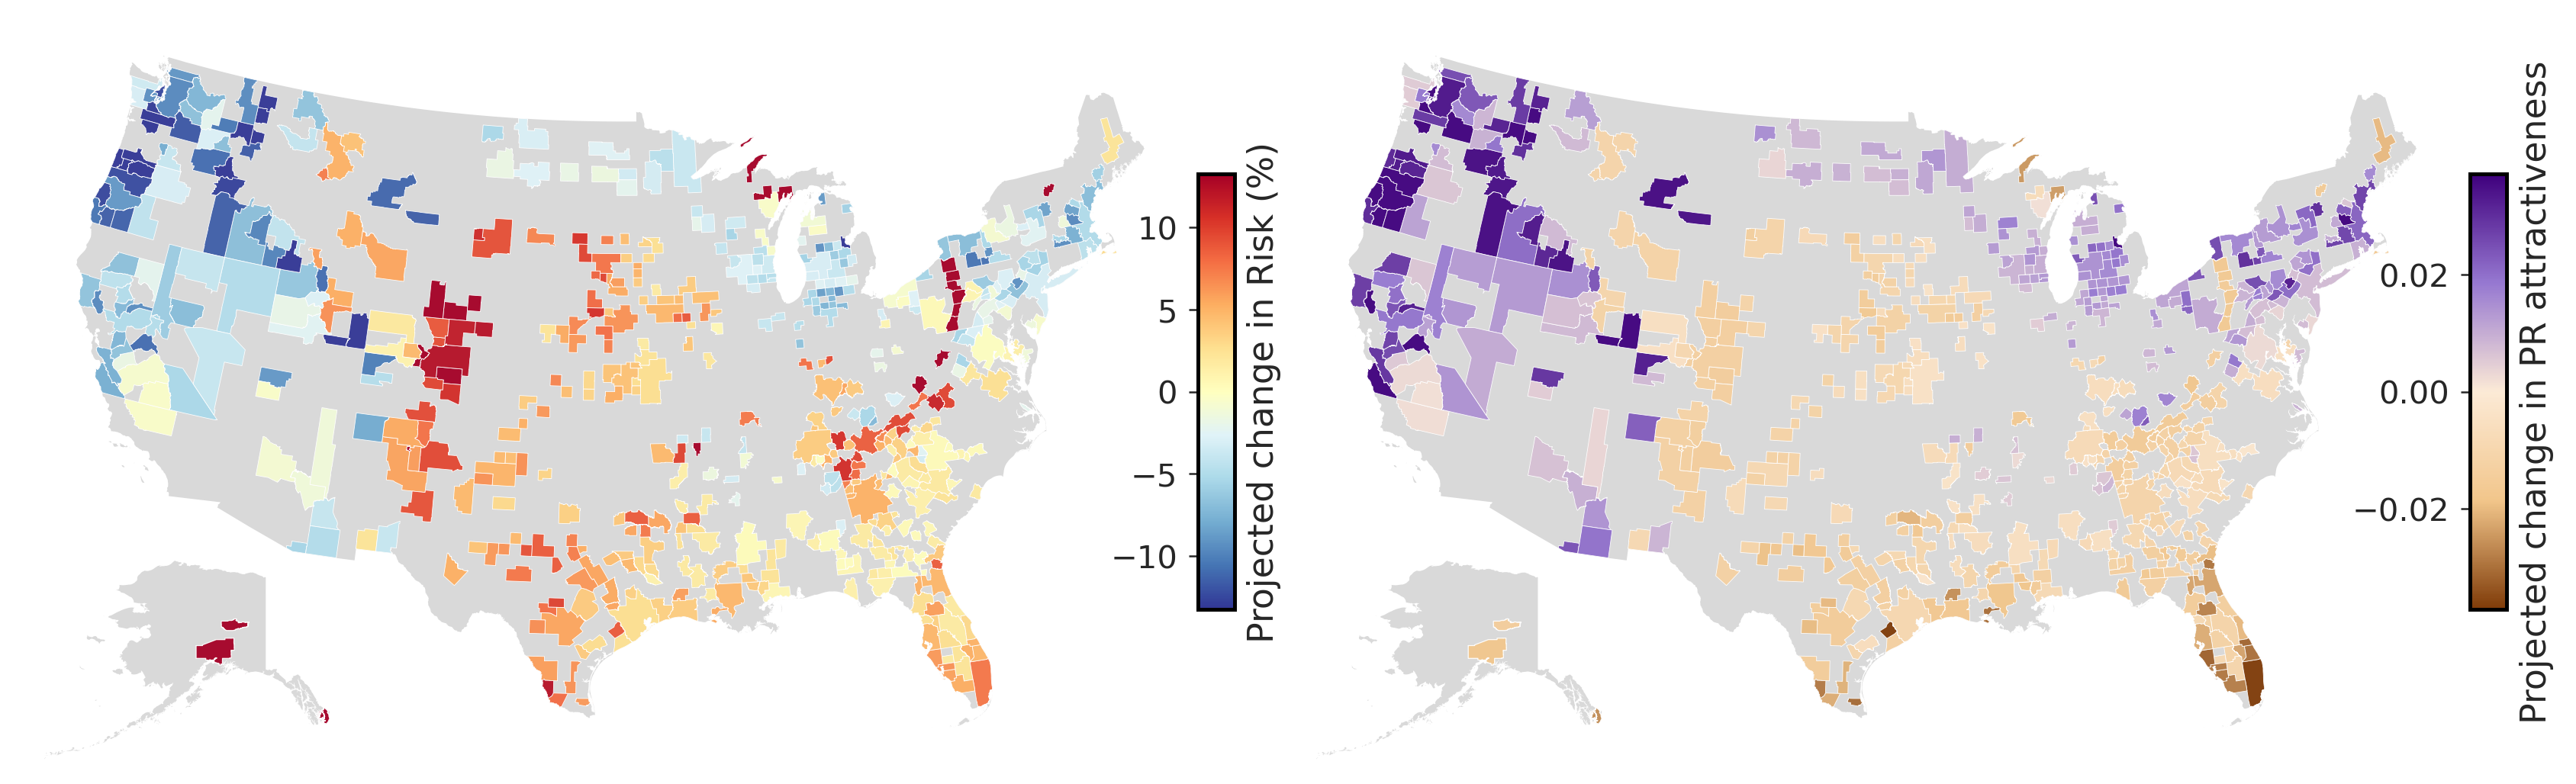

In [26]:
# -------------------------------------------------------
# Prepare data
# -------------------------------------------------------
cbsa_agg_sig=cbsa_agg[cbsa_agg['significant']==True]

counties_5070 = counties.to_crs("EPSG:5070")
counties_4269 = counties.to_crs("EPSG:4269")
usa = cbsa_agg_sig.to_crs("EPSG:5070")
usa_4269 = cbsa_agg_sig.to_crs("EPSG:4269")

conus = usa[~usa["CBSA"].isin(cbsa_ak_hi)]
alaska = usa_4269[usa_4269["CBSA"].isin([str(x) for x in [11260, 21820, 27940, 16220, 28540]])]
hawaii = usa_4269[usa_4269["CBSA"].isin([str(x) for x in [46520, 27980, 25900, 28180]])]

conus_counties = counties_5070[~counties_5070["STATEFP"].isin(not_conus)].copy()
alaska_counties = counties_4269[counties_4269["STATEFP"] == "02"].copy()
hawaii_counties = counties_4269[counties_4269["STATEFP"] == "15"].copy()

conus_outline  = conus_counties[["geometry"]].dissolve()
alaska_outline = alaska_counties[["geometry"]].dissolve()
hawaii_outline = hawaii_counties[["geometry"]].dissolve()

prc_change = "haz_composite_LATE_PCT_CHANGE"
attr_col   = "attractiveness_change"

# -------------------------------------------------------
# Normalisation
# -------------------------------------------------------
pct_vmax  = np.nanpercentile(conus[prc_change], 97)
pct_norm  = TwoSlopeNorm(vmin=-pct_vmax, vcenter=0, vmax=pct_vmax)

attr_vmax = np.nanpercentile(conus[attr_col], 97)
attr_norm = TwoSlopeNorm(vmin=-attr_vmax, vcenter=0, vmax=attr_vmax)

# -------------------------------------------------------
# Helper: draw AK + HI insets on a given axis
# -------------------------------------------------------
def add_ak_hi_insets(ax, column, cmap, norm):
    """Add Alaska and Hawaii insets to the given axes."""

    # --- Alaska inset ---
    ax_ak = inset_axes(
        ax,
        width="100%", height="100%",
        loc="lower left",
        bbox_to_anchor=(0.00, 0.00, 0.28, 0.28),
        bbox_transform=ax.transAxes,
        borderpad=0
    )
    ax_ak.axis("off")

    alaska_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_ak, zorder=1)
    alaska.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.3,
        edgecolor="white",
        ax=ax_ak,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"}
    )
    ax_ak.set_xlim(-180, -129)
    ax_ak.set_ylim(51, 72)

    # # --- Hawaii inset ---
    # ax_hi = inset_axes(
    #     ax,
    #     width="100%", height="100%",
    #     loc="lower left",
    #     bbox_to_anchor=(0.24, 0.02, 0.18, 0.18),
    #     bbox_transform=ax.transAxes,
    #     borderpad=0
    # )
    # ax_hi.axis("off")

    # hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi, zorder=1)
    # hawaii.plot(
    #     column=column,
    #     cmap=cmap,
    #     norm=norm,
    #     linewidth=0.3,
    #     ax=ax_hi,
    #     alpha=0.95,
    #     zorder=2,
    #     missing_kwds={"color": "none"}
    # )
    # ax_hi.set_xlim(-161, -154)
    # ax_hi.set_ylim(18, 23)


# -------------------------------------------------------
# Plot
# -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"wspace": 0.05})

for ax, column, cmap, norm, label in [
    (axes[0], prc_change, 'RdYlBu_r', pct_norm,  "Projected change in Risk (%)"),
    (axes[1], attr_col,  strong_puor, attr_norm, "Projected change in PR attractiveness"),
]:
    # Background
    conus_outline.plot(color="#d9d9d9", linewidth=0, ax=ax, zorder=1)

    # CONUS choropleth
    conus.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="white",
        ax=ax,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"},
    )
    ax.axis("off")

    # AK + HI insets
    add_ak_hi_insets(ax, column, cmap, norm)

    # Colourbar (overlaid on the left side of each panel)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm._A = []
    cbar = fig.colorbar(
        sm, ax=ax,
        orientation="vertical",
        fraction=0.03,
        pad=0,
        aspect=12
    )
    cbar.ax.yaxis.set_ticks_position('left')
    cbar.ax.tick_params(labelleft=True, labelright=False)
    cbar.ax.yaxis.set_label_position('right')
    cbar.set_label(label)

# plt.tight_layout()
plt.savefig(
    '../fig/projections_composite_cbsa2_sig.png',
    bbox_inches='tight',
    dpi=300
)
plt.show()

In [27]:
hits_irs=pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")
hits_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_exp_1122.parquet")

hits_merged=hits_irs.merge(hits_exp, left_on=['CBSA'], right_on=['CBSA'], how='inner', suffixes=('_irs', '_exp'))

hits_merged['pagerank_diff']=hits_merged['pagerank_exp']-hits_merged['pagerank_irs']
for col in ["pagerank_irs", "pagerank_exp"]:
    hits_merged[f"log_{col}"] = (hits_merged[col] + 1e-12).apply(np.log)

hits_merged['pagerank_logdiff']=hits_merged['log_pagerank_exp']-hits_merged['log_pagerank_irs']


xwalk = cbsa[['STCOFIPS', 'CBSA Code', 'CBSA Title']].drop_duplicates()
counties = counties.merge(xwalk, on='STCOFIPS', how='left')
nri_county = nri_county.merge(xwalk, on='STCOFIPS', how='left')

nri_cbsa = (
    nri_county
    .dropna(subset=['CBSA Code'])
    .assign(POPULATION=pd.to_numeric(nri_county['POPULATION'], errors='coerce'))
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        POPULATION=('POPULATION', 'sum')
    )
)

In [28]:
cbsa_agg=cbsa_agg.merge(hits_merged[['CBSA', 'pagerank_logdiff', 'log_pagerank_exp']], on='CBSA', how='left')
cbsa_agg=cbsa_agg.merge(nri_cbsa[['CBSA Code', 'POPULATION']], left_on='CBSA', right_on='CBSA Code', how='left')

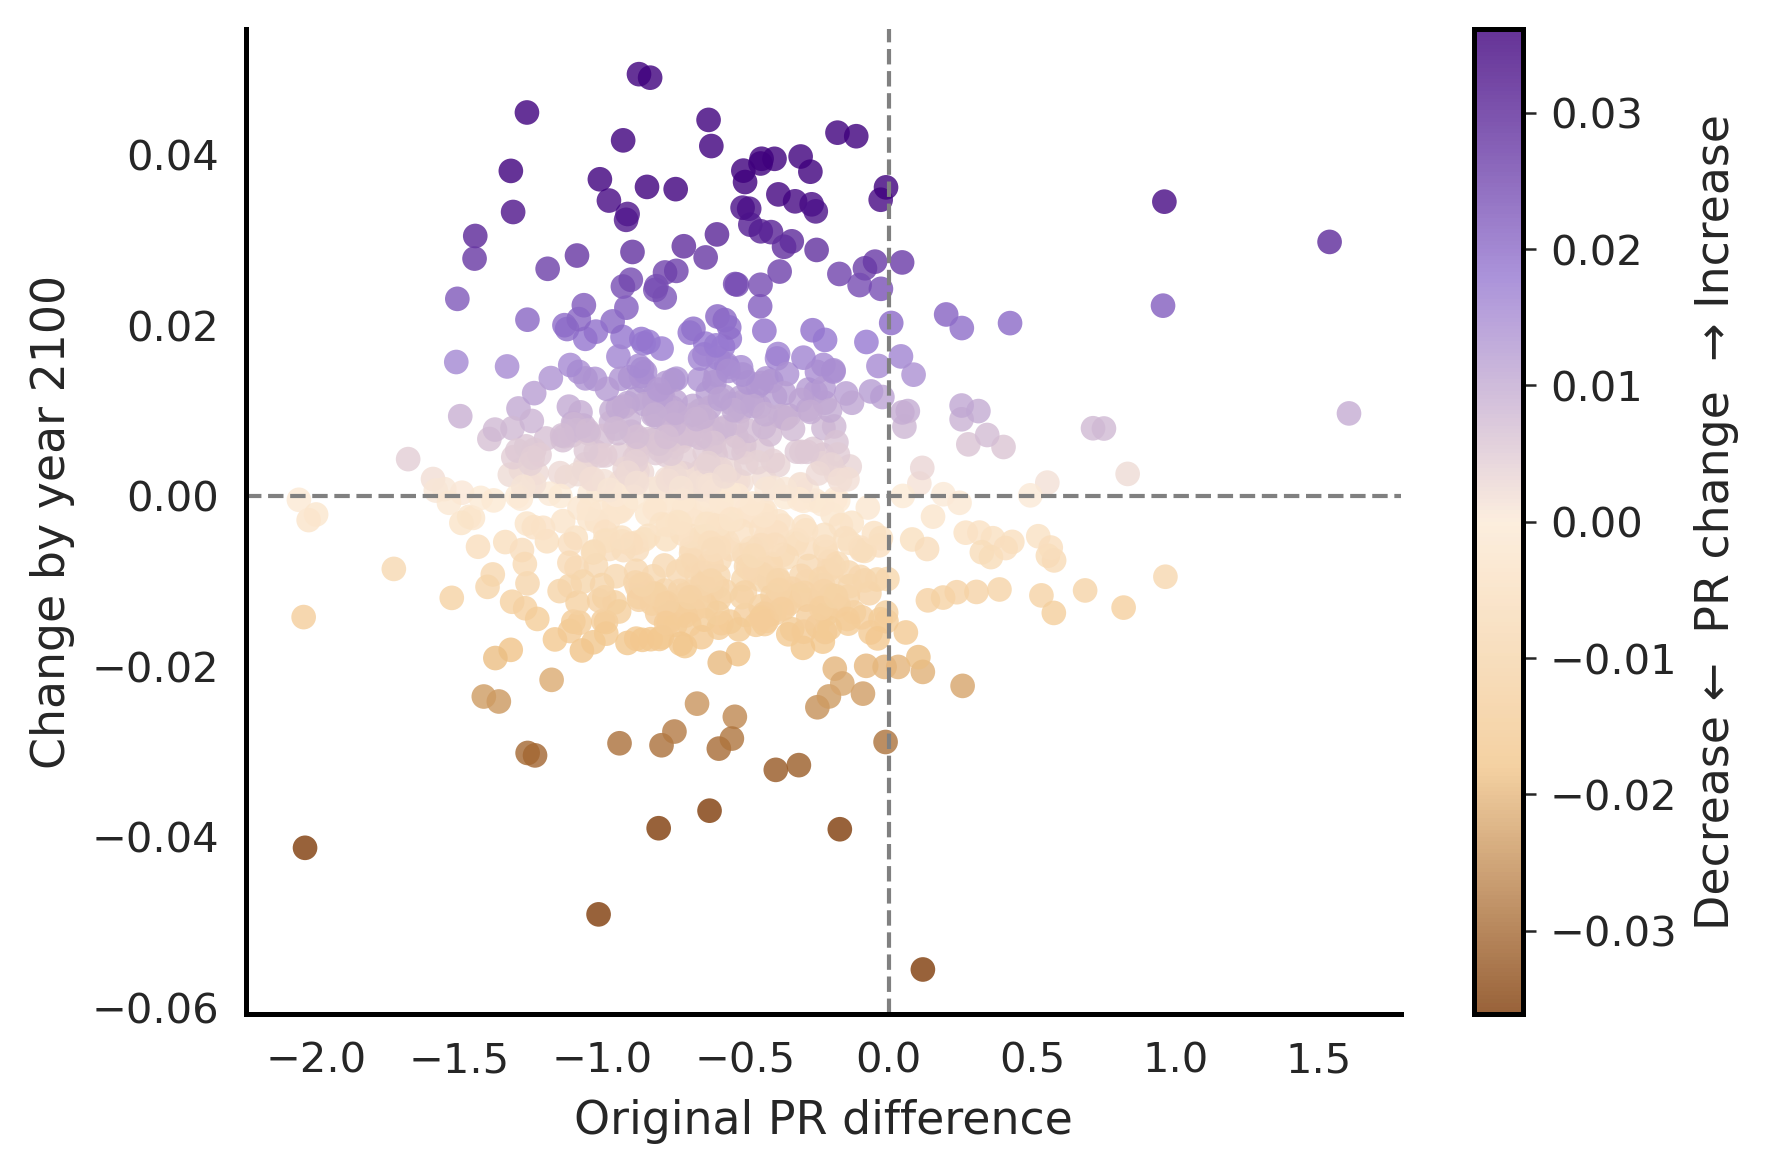

In [29]:
# --- data ---
x = cbsa_agg["pagerank_logdiff"]
y = cbsa_agg["attractiveness_change"]

mask = x.notna() & y.notna()
x = x[mask]
y = y[mask]

# --- color normalisation (symmetric) ---
vmax = np.nanpercentile(np.abs(y), 97)
norm = mpl.colors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

# --- plot ---
fig, ax = plt.subplots(figsize=(6, 4))

sc = ax.scatter(
    x, y,
    c=y,
    cmap=strong_puor,
    norm=norm,
    s=35,
    edgecolor="none",
    alpha=0.8
)

# reference lines
ax.axhline(0, linestyle="--", color="gray", lw=1)
ax.axvline(0, linestyle="--", color="gray", lw=1)

# labels
ax.set_xlabel("Original PR difference")
ax.set_ylabel("Change by year 2100")

# spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis="both")

# colorbar
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Decrease ←  PR change  → Increase")


plt.tight_layout()
plt.show()

In [30]:
# Ensure CBSA code is string with leading zeros
cbsa["CBSA Code"] = cbsa["CBSA Code"].astype(str).str.zfill(5)

# Count counties per CBSA-state combination
county_counts = (
    cbsa
    .groupby(["CBSA Code", "State Name"])
    .size()
    .reset_index(name="n_counties")
)

# Assign each CBSA to the state with the most counties
cbsa_to_state = (
    county_counts
    .sort_values("n_counties", ascending=False)
    .drop_duplicates(subset="CBSA Code", keep="first")
    [["CBSA Code", "State Name"]]
)

# Merge back into your main geodataframe
cbsa_agg = cbsa_agg.merge(cbsa_to_state, left_on="CBSA", right_on='CBSA Code', how="left")

In [31]:
states_grouped_pop = (
    cbsa_agg
    .groupby("State Name")
    .apply(
        lambda df: (
            lambda d: np.nan
            if d["POPULATION"].sum() == 0
            else np.average(
                d["attractiveness_change"],
                weights=d["POPULATION"]
            )
        )(
            df.dropna(subset=["attractiveness_change", "POPULATION"])
        )
    )
)

states_grouped_pr = (
            cbsa_agg
            .groupby("State Name")
            .apply(
                lambda df: (
                    lambda d: np.nan
                    if d["POPULATION"].sum() == 0
                    else np.average(
                        d["attractiveness_change"],
                        weights=d["log_pagerank_exp"]
                    )
                )(
                    df.dropna(subset=["attractiveness_change", "log_pagerank_exp"])
                )
            )
        )

In [32]:
# drop missing
s = states_grouped_pop.dropna()

bottom5 = s.nsmallest(5)
top5    = s.nlargest(5)

plot_data = pd.concat([bottom5, top5]).sort_values(ascending=True)

In [33]:
vmax = np.nanpercentile(np.abs(plot_data.values), 97)
norm = mpl.colors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

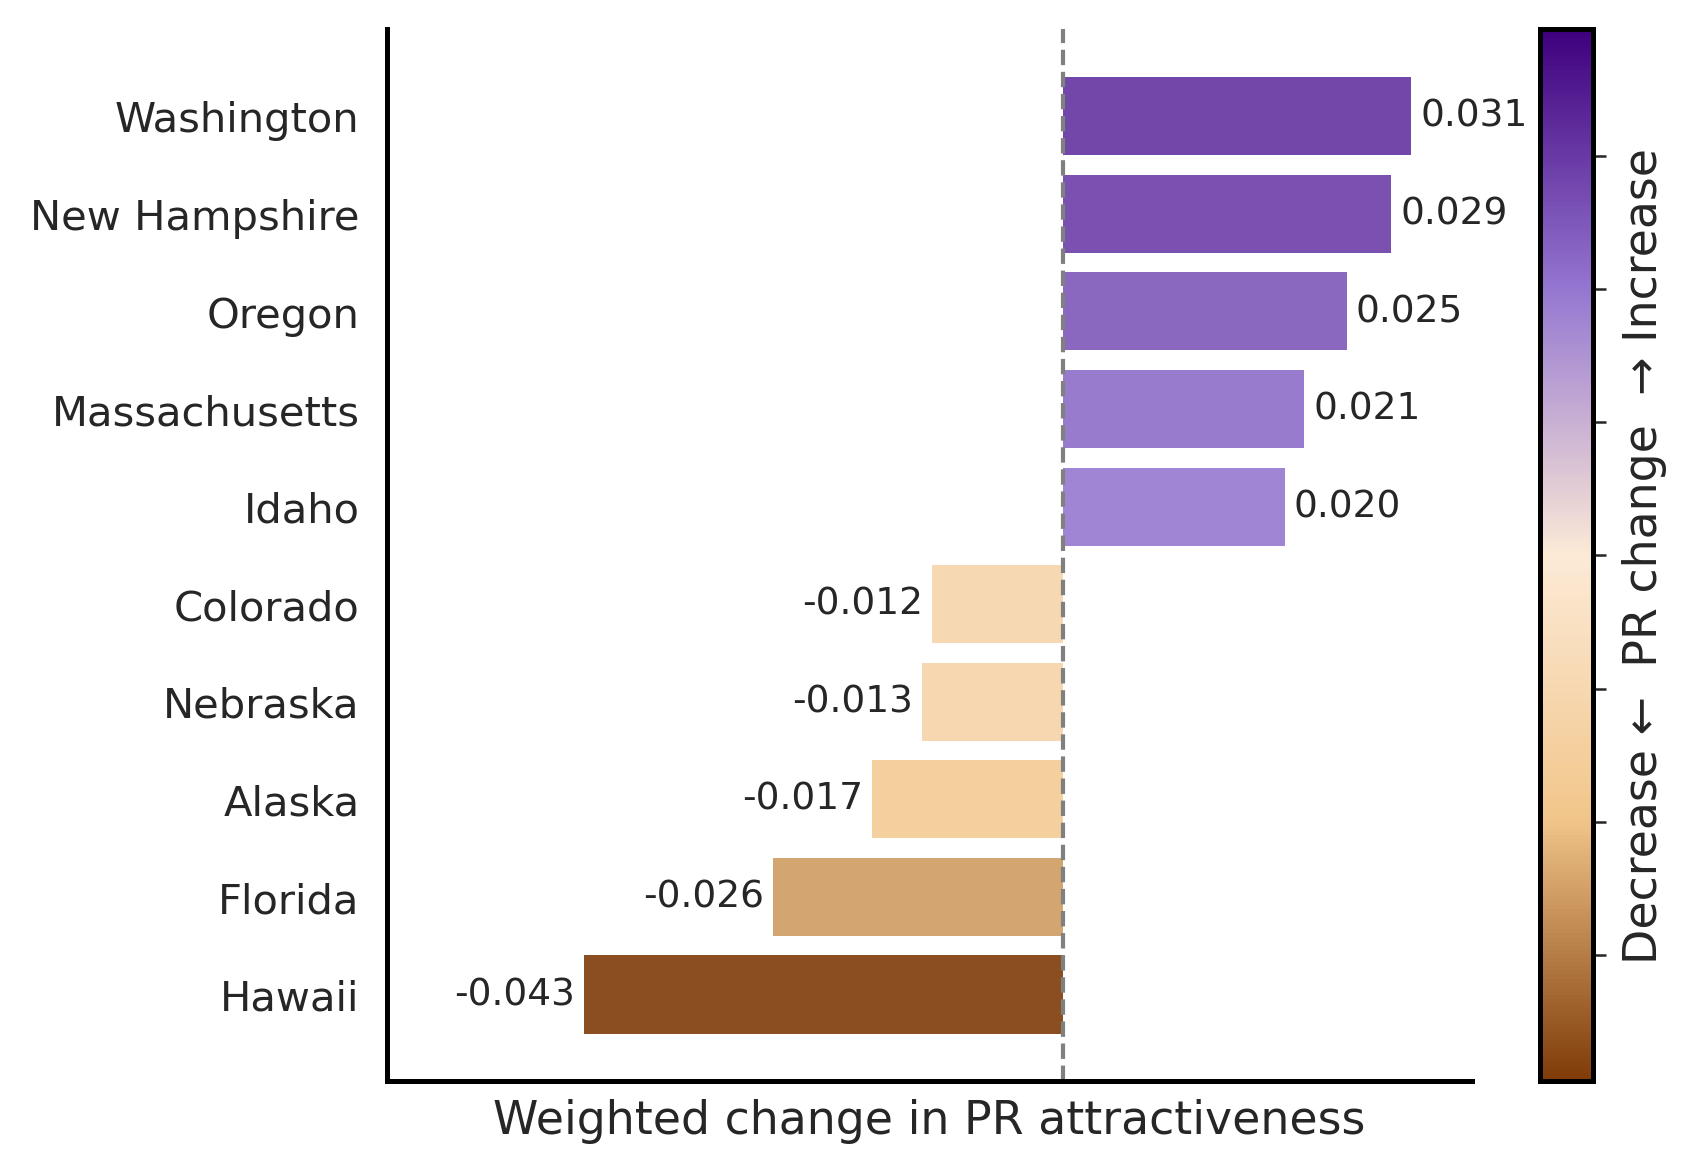

In [34]:
fig, ax = plt.subplots(figsize=(6, 4))

colors = strong_puor(norm(plot_data.values))

ax.barh(
    plot_data.index,
    plot_data.values,
    color=colors,
    edgecolor="none",
    alpha=0.9
)

# zero reference
ax.axvline(0, linestyle="--", color="gray", lw=1)

# labels
ax.set_xlabel("Weighted change in PR attractiveness")
ax.set_ylabel("")

# spines (same as scatter)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)
ax.tick_params(axis="x", bottom=False, labelbottom=False)

# value annotations (subtle)
for i, v in enumerate(plot_data.values):
    ax.text(
        v + np.sign(v) * 0.02 * vmax,
        i,
        f"{v:.3f}",
        va="center",
        ha="left" if v > 0 else "right",
        fontsize=9
    )

sm = mpl.cm.ScalarMappable(norm=norm, cmap=strong_puor)
sm._A = []

cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Decrease ←  PR change  → Increase")
cbar.ax.tick_params(labelleft=False, labelright=False)

xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin * 1.3, xmax * 1.05)


plt.tight_layout()
plt.show()


In [35]:
risk_ate = cates_all.loc[cates_all['hazard'] == 'HWAV_RISKS', 'ATE_est'].iloc[0]

In [36]:
risk_ate

-0.0014714369022572

In [37]:
cbsa_agg.columns

Index(['CBSA', 'name', 'geometry', 'CBSA Code_x', 'CBSA Title', 'CFLD_RISKS',
       'DRGT_RISKS', 'EXHT_RISKS', 'HRCN_RISKS', 'WFIR_RISKS',
       'CFLD_LATE_MEAN_PRISKS', 'DRGT_LATE_MEAN_PRISKS',
       'EXHT_L99_LATE_MEAN_PRISKS', 'HRCN_LATE_MEAN_PRISKS',
       'WFIR_LATE_MEAN_PRISKS', 'haz_composite_mean', 'haz_composite_late',
       'CFLD_LATE_PCT_CHANGE', 'DRGT_LATE_PCT_CHANGE', 'EXHT_LATE_PCT_CHANGE',
       'HRCN_LATE_PCT_CHANGE', 'WFIR_LATE_PCT_CHANGE', 'haz_composite_RISKS',
       'haz_composite_LATE_PCT_CHANGE', 'risk_change', 'risk_change_cfld',
       'risk_change_drgt', 'risk_change_exht', 'risk_change_hrcn',
       'risk_change_wfir', 'attractiveness_change',
       'attractiveness_change_var', 'attractiveness_change_se',
       'attractiveness_change_ci_low', 'attractiveness_change_ci_high',
       'significant', 'pagerank_logdiff', 'log_pagerank_exp', 'CBSA Code_y',
       'POPULATION', 'CBSA Code', 'State Name'],
      dtype='object')

In [38]:
cbsa_agg['risk_change_heat']=cbsa_agg['EXHT_L99_LATE_MEAN_PRISKS']-cbsa_agg['EXHT_RISKS']
cbsa_agg['attractiveness_change_heat']=cbsa_agg['risk_change_heat']*risk_ate

In [39]:
cbsa_agg['EXHT_LATE_PCT_CHANGE'].quantile(0.85)

47.37048765719654

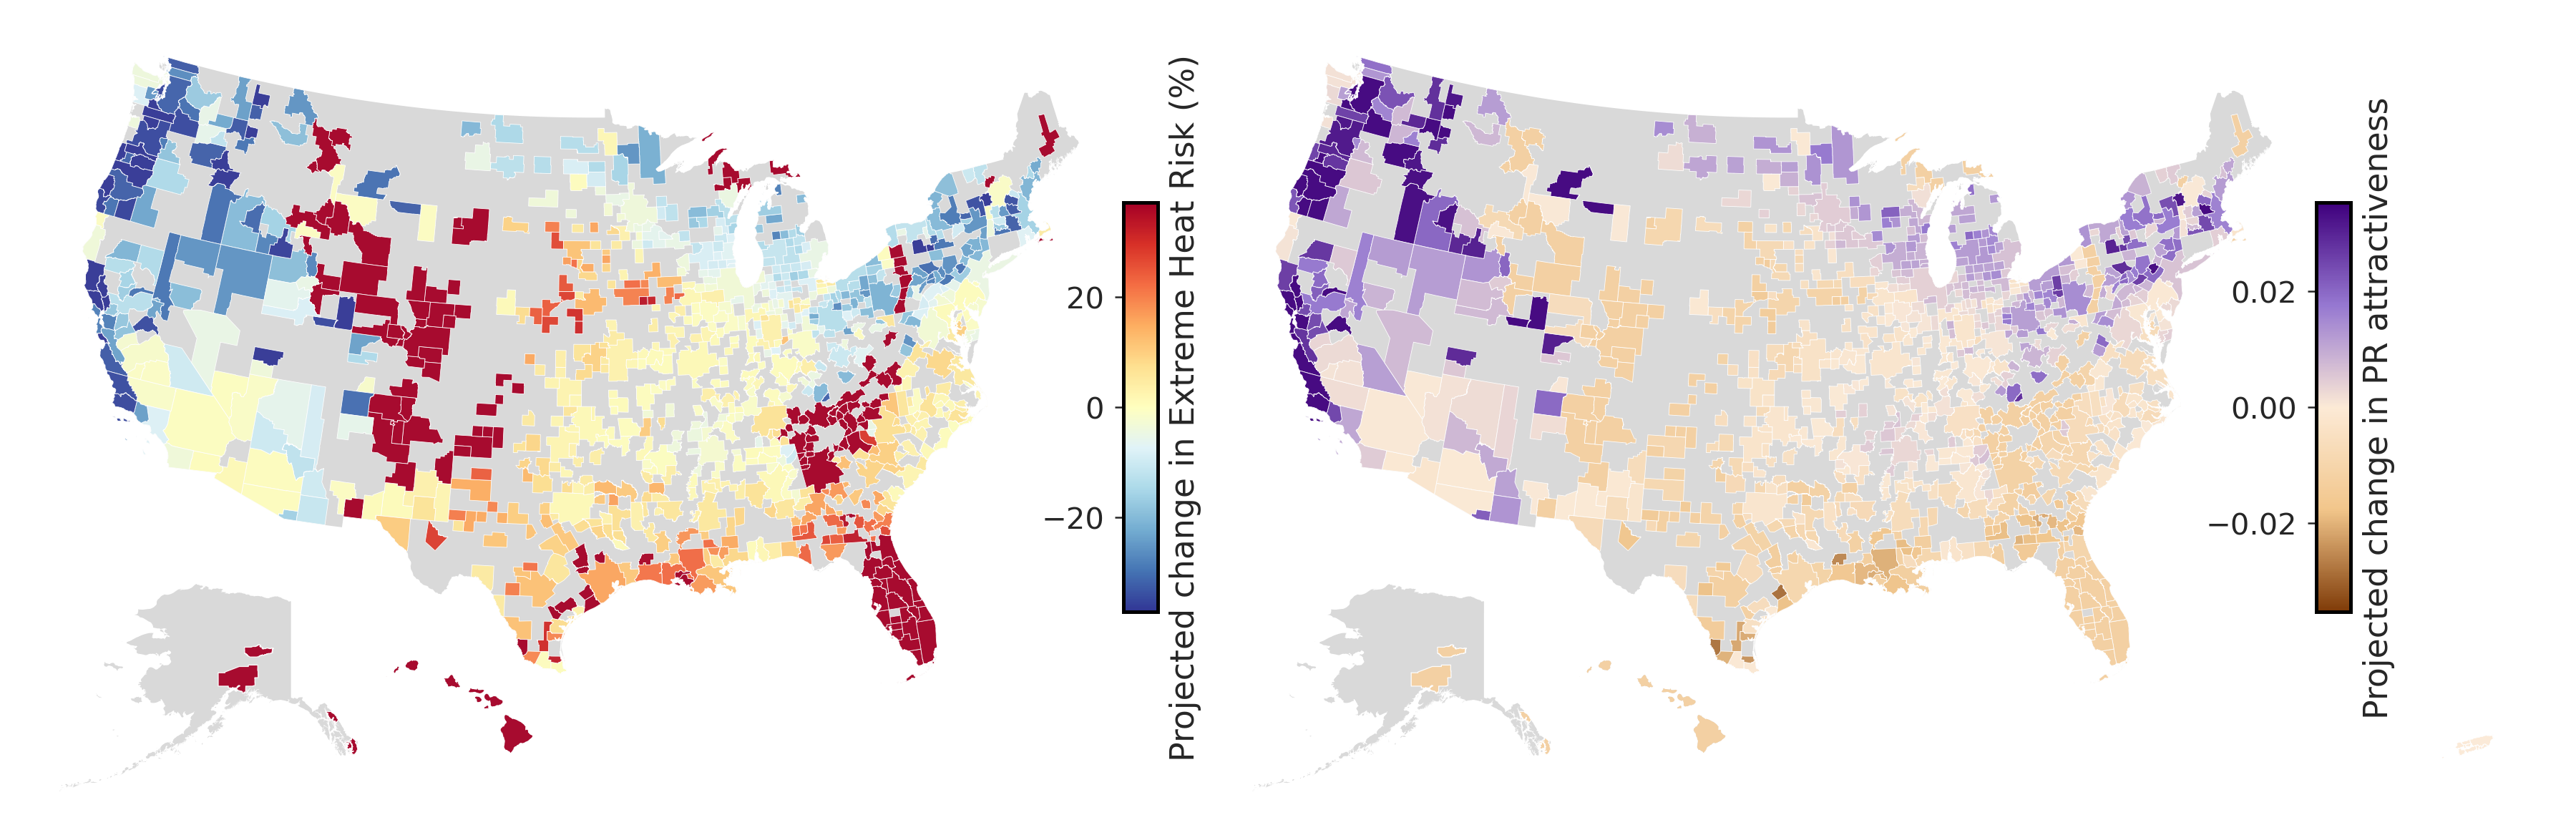

In [40]:
## for heat

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# no Alaska, no Hawaii: cbsa codes for alaska and hawaii
cbsa_ak_hi = [
    11260, 21820, 27940, 16220, 28540,  # Alaska
    46520, 27980, 25900, 28180           # Hawaii
]
cbsa_ak_hi = [str(x) for x in cbsa_ak_hi]
not_conus = ["02", "15", "72", "78", "60", "66", "69"]

# -------------------------------------------------------
# Prepare data
# -------------------------------------------------------
counties_5070 = counties.to_crs("EPSG:5070")
counties_4269 = counties.to_crs("EPSG:4269")
usa = cbsa_agg.to_crs("EPSG:5070")
usa_4269 = cbsa_agg.to_crs("EPSG:4269")

conus = usa[~usa["CBSA"].isin(cbsa_ak_hi)]
alaska = usa_4269[usa_4269["CBSA"].isin([str(x) for x in [11260, 21820, 27940, 16220, 28540]])]
hawaii = usa_4269[usa_4269["CBSA"].isin([str(x) for x in [46520, 27980, 25900, 28180]])]

conus_counties = counties_5070[~counties_5070["STATEFP"].isin(not_conus)].copy()
alaska_counties = counties_4269[counties_4269["STATEFP"] == "02"].copy()
hawaii_counties = counties_4269[counties_4269["STATEFP"] == "15"].copy()

conus_outline  = conus_counties[["geometry"]].dissolve()
alaska_outline = alaska_counties[["geometry"]].dissolve()
hawaii_outline = hawaii_counties[["geometry"]].dissolve()

prc_change = "EXHT_LATE_PCT_CHANGE"
attr_col   = "attractiveness_change_heat"

# -------------------------------------------------------
# Normalisation
# -------------------------------------------------------
pct_vmax  = np.nanpercentile(conus[prc_change], 85)
pct_norm  = TwoSlopeNorm(vmin=-pct_vmax, vcenter=0, vmax=pct_vmax)

attr_vmax = np.nanpercentile(conus[attr_col], 97)
attr_norm = TwoSlopeNorm(vmin=-attr_vmax, vcenter=0, vmax=attr_vmax)

# -------------------------------------------------------
# Helper: draw AK + HI insets on a given axis
# -------------------------------------------------------
def add_ak_hi_insets(ax, column, cmap, norm):
    """Add Alaska and Hawaii insets to the given axes."""

    # --- Alaska inset ---
    ax_ak = inset_axes(
        ax,
        width="100%", height="100%",
        loc="lower left",
        bbox_to_anchor=(0.00, 0.00, 0.28, 0.28),
        bbox_transform=ax.transAxes,
        borderpad=0
    )
    ax_ak.axis("off")

    alaska_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_ak, zorder=1)
    alaska.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.3,
        edgecolor="white",
        ax=ax_ak,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"}
    )
    ax_ak.set_xlim(-180, -129)
    ax_ak.set_ylim(51, 72)

    # --- Hawaii inset ---
    ax_hi = inset_axes(
        ax,
        width="100%", height="100%",
        loc="lower left",
        bbox_to_anchor=(0.24, 0.02, 0.18, 0.18),
        bbox_transform=ax.transAxes,
        borderpad=0
    )
    ax_hi.axis("off")

    hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi, zorder=1)
    hawaii.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0,
        ax=ax_hi,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"}
    )
    ax_hi.set_xlim(-161, -154)
    ax_hi.set_ylim(18, 23)


# -------------------------------------------------------
# Plot
# -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"wspace": 0.05})

for ax, column, cmap, norm, label in [
    (axes[0], prc_change, 'RdYlBu_r', pct_norm,  "Projected change in Extreme Heat Risk (%)"),
    (axes[1], attr_col,  strong_puor, attr_norm, "Projected change in PR attractiveness"),
]:
    # Background
    conus_outline.plot(color="#d9d9d9", linewidth=0, ax=ax, zorder=1)

    # CONUS choropleth
    conus.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="white",
        ax=ax,
        alpha=0.95,
        zorder=2,
        missing_kwds={"color": "none"},
    )
    ax.axis("off")

    # AK + HI insets
    add_ak_hi_insets(ax, column, cmap, norm)

    # Colourbar (overlaid on the left side of each panel)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm._A = []
    cbar = fig.colorbar(
        sm, ax=ax,
        orientation="vertical",
        fraction=0.03,
        pad=-0.21,
        aspect=12
    )
    cbar.ax.yaxis.set_ticks_position('left')
    cbar.ax.tick_params(labelleft=True, labelright=False)
    cbar.ax.yaxis.set_label_position('right')
    cbar.set_label(label)

# plt.tight_layout()
plt.savefig(
    '../fig/si/projections_heat_cbsa2.png',
    bbox_inches='tight',
    dpi=300
)
plt.show()